Using device: cpu
Epoch 01 | D Loss: 0.3615 | G Loss: 1.7796


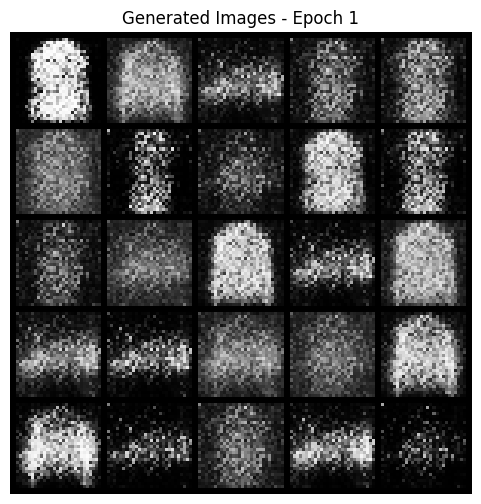

Epoch 02 | D Loss: 0.3175 | G Loss: 2.6568
Epoch 03 | D Loss: 0.3793 | G Loss: 2.2912
Epoch 04 | D Loss: 0.4002 | G Loss: 2.1443
Epoch 05 | D Loss: 0.4027 | G Loss: 2.0590


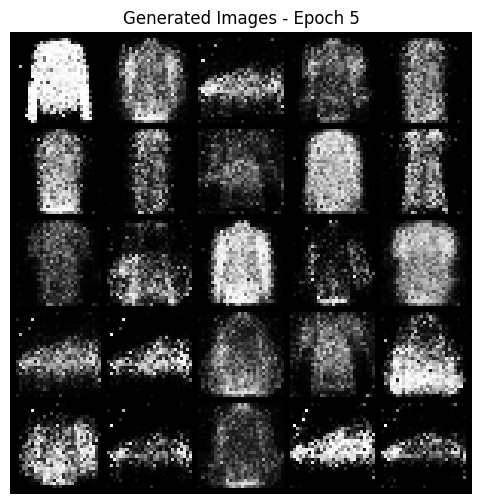

Epoch 06 | D Loss: 0.4205 | G Loss: 1.9223
Epoch 07 | D Loss: 0.4192 | G Loss: 1.9904
Epoch 08 | D Loss: 0.4440 | G Loss: 1.8508
Epoch 09 | D Loss: 0.4552 | G Loss: 1.8081
Epoch 10 | D Loss: 0.4510 | G Loss: 1.8149


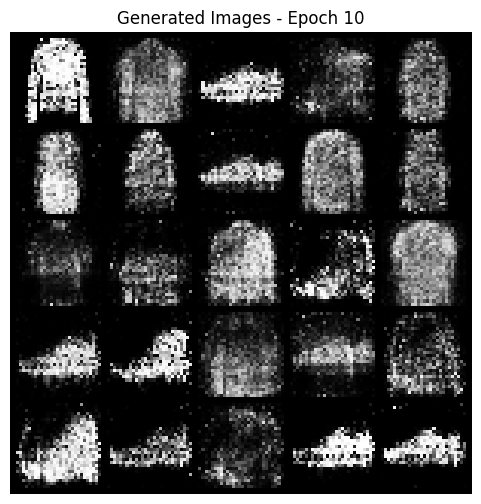

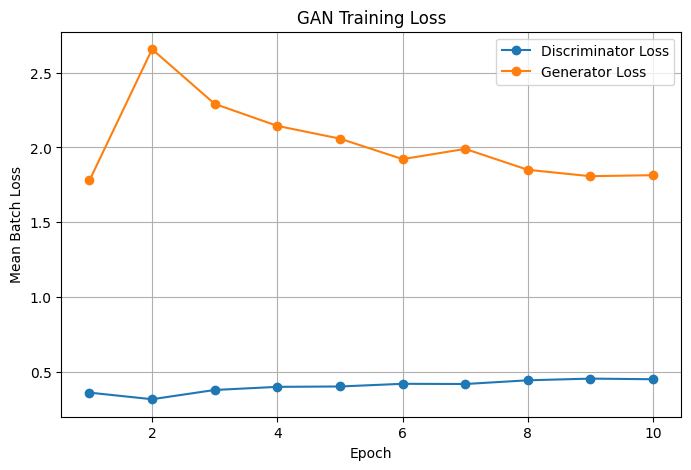

Training Completed Successfully
Saved files: [PosixPath('lab_outputs/gan_epoch_05.png'), PosixPath('lab_outputs/fashion_discriminator.pt'), PosixPath('lab_outputs/fashion_generator.pt'), PosixPath('lab_outputs/gan_epoch_01.png'), PosixPath('lab_outputs/gan_epoch_10.png'), PosixPath('lab_outputs/gan_losses.png')]


In [4]:

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

out = Path("lab_outputs")
out.mkdir(exist_ok=True)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    drop_last=True
)

latent_dim = 64

G = nn.Sequential(
    nn.Linear(latent_dim, 256),
    nn.LeakyReLU(0.2),
    nn.Linear(256, 512),
    nn.LeakyReLU(0.2),
    nn.Linear(512, 784),
    nn.Tanh()
).to(device)

D = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 512),
    nn.LeakyReLU(0.2),
    nn.Linear(512, 256),
    nn.LeakyReLU(0.2),
    nn.Linear(256, 1)
).to(device)

loss_fn = nn.BCEWithLogitsLoss()

opt_g = torch.optim.Adam(
    G.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

opt_d = torch.optim.Adam(
    D.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

fixed_z = torch.randn(25, latent_dim, device=device)

def generate_grid(epoch):
    G.eval()
    with torch.no_grad():
        images = G(fixed_z).reshape(-1, 1, 28, 28)
        images = (images + 1) / 2
        grid = make_grid(images.cpu(), nrow=5)

    plt.figure(figsize=(6, 6))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.title(f"Generated Images - Epoch {epoch}")
    plt.axis("off")
    plt.savefig(out / f"gan_epoch_{epoch:02d}.png")
    plt.show()
    G.train()

def train_batch(real):
    batch_size = real.size(0)

    real = real.to(device)
    noise = torch.randn(batch_size, latent_dim, device=device)
    fake = G(noise)

    real_output = D(real)
    fake_output = D(fake.detach())

    real_labels = torch.ones_like(real_output)
    fake_labels = torch.zeros_like(fake_output)

    d_loss_real = loss_fn(real_output, real_labels)
    d_loss_fake = loss_fn(fake_output, fake_labels)

    d_loss = (d_loss_real + d_loss_fake) / 2

    opt_d.zero_grad()
    d_loss.backward()
    opt_d.step()

    D.requires_grad_(False)

    opt_g.zero_grad()

    generated_output = D(fake)
    g_loss = loss_fn(
        generated_output,
        torch.ones_like(generated_output)
    )

    g_loss.backward()
    opt_g.step()

    D.requires_grad_(True)

    return d_loss.item(), g_loss.item()

history = []

for epoch in range(1, 11):
    d_losses = []
    g_losses = []

    for real, _ in train_loader:
        d_loss, g_loss = train_batch(real)
        d_losses.append(d_loss)
        g_losses.append(g_loss)

    avg_d = sum(d_losses) / len(d_losses)
    avg_g = sum(g_losses) / len(g_losses)

    history.append((avg_d, avg_g))

    print(
        f"Epoch {epoch:02d} | "
        f"D Loss: {avg_d:.4f} | "
        f"G Loss: {avg_g:.4f}"
    )

    if epoch in [1, 5, 10]:
        generate_grid(epoch)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    [x[0] for x in history],
    marker="o",
    label="Discriminator Loss"
)

plt.plot(
    range(1, 11),
    [x[1] for x in history],
    marker="o",
    label="Generator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Batch Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid()
plt.savefig(out / "gan_losses.png")
plt.show()

torch.save(G.state_dict(), out / "fashion_generator.pt")
torch.save(D.state_dict(), out / "fashion_discriminator.pt")

print("Training Completed Successfully")
print("Saved files:", list(out.iterdir()))
